In [1]:
# zebrafish L = 3 的结果不是想要的。 在L = 6 的时候10 2 6，20 2 6 也不是想要的。

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.sparse import csr_matrix
import scvelo as scv
from torch.optim import SGD, Adam, Adagrad
from function import *

from utils import *
from g2g_model_Fisher import *
import itertools

In [3]:
data_path = "/home/linux/桌面/SCIM-main/main/data/branch_data/"
path_path = "/home/linux/桌面/Is single cell sloppy?/4_FI_vs_Velocity/RC_path/"
cmap = plt.colormaps['Spectral_r']
save = False

[k_nei, K, L] = [10, 3, 3]
computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 3386 × 600
    obs: 'split_id', 'sample', 'Size_Factor', 'condition', 'Cluster', 'celltype', 'umap_1', 'umap_2', 'batch', 'n_counts', 'Cell_type', 'voronoi_id_Schwann Cell', 'voronoi_id_Xanthophore', 'voronoi_id_Melanophore'
    var: 'n_cells', 'gene_count_corr', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'Cell_type_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap', 'velocity_params'
    obsm: 'X_eigengene', 'X_hotspot', 'X_

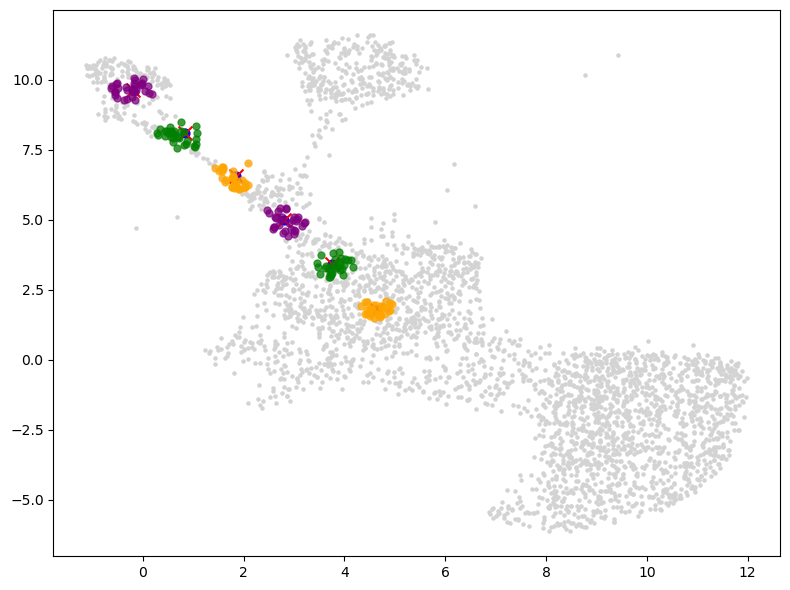

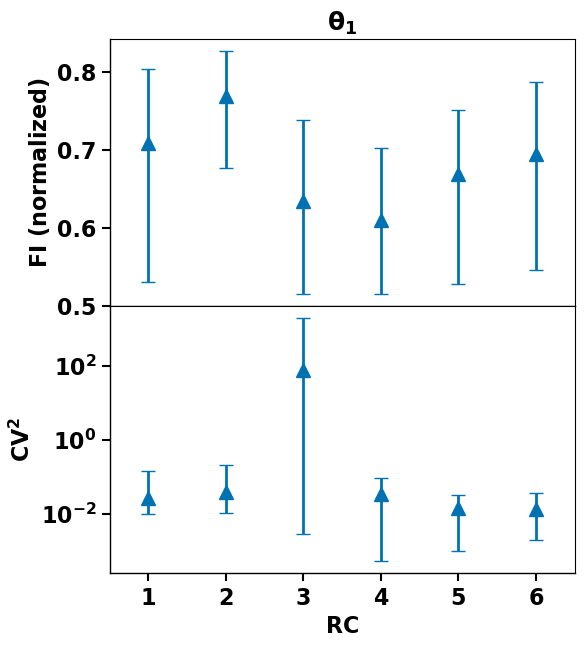

y: [2.6587570e-02 3.8856104e-02 7.8075691e+01 3.5776254e-02 1.4343246e-02
 1.3346344e-02]
max_vals: [1.4554676e-01 2.1028434e-01 1.9353973e+03 9.1655180e-02 3.2822426e-02
 3.7700254e-02]
min_vals: [0.00994253 0.01038705 0.00289607 0.00053748 0.00101588 0.00203873]
error: [[1.66450441e-02 2.84690559e-02 7.80727921e+01 3.52387726e-02
  1.33273676e-02 1.13076176e-02]
 [1.18959196e-01 1.71428233e-01 1.85732166e+03 5.58789261e-02
  1.84791796e-02 2.43539102e-02]]
y: [0.01317862 0.0020297  0.00806091 0.00598015 0.01608531 0.00598241]
max_vals: [0.02936061 0.00518919 0.028807   0.08538334 0.05586605 0.01423039]
min_vals: [0.00229707 0.00113143 0.00291695 0.00076465 0.00757067 0.00062055]
error: [[0.01088155 0.00089827 0.00514396 0.0052155  0.00851464 0.00536186]
 [0.01618198 0.00315949 0.02074609 0.07940318 0.03978074 0.00824799]]
y: [5.197991   4.361335   0.02134741 0.01111631 0.07926393 0.01901183]
max_vals: [1.2088892e+02 9.4864067e+01 6.4048104e-02 1.9983130e-02 9.7419101e-01
 4.8673738e-

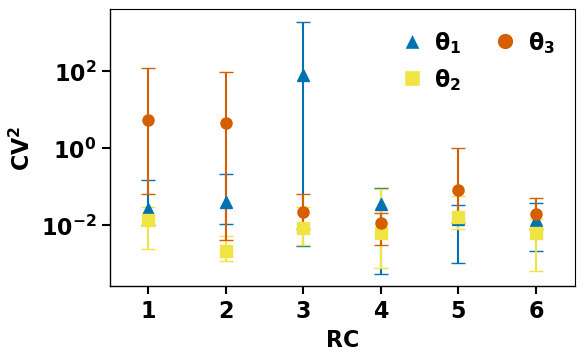

pca_svd_rc_mean_all:
[[[ -4.0134845   -8.521918    -3.177474  ]
  [ -3.2705727   -7.865584     2.9768052 ]
  [ -3.42838     -8.766822     4.3131614 ]
  [ -3.5225298    9.083683    -2.6135561 ]
  [ -3.1127856   -8.560587     3.686607  ]
  [ -2.1397178   -8.902032     4.9890413 ]
  [ -2.9997878   -9.432261     1.7797145 ]
  [ -1.303887    -9.124239     3.9714658 ]
  [ -2.0425677   -9.315253     4.773157  ]
  [ -2.1482337    9.165234    -0.54788667]
  [ -4.14847      8.437147     2.8667068 ]
  [ -4.006938     8.10962     -2.7715042 ]
  [ -4.023387    -9.592338     0.14409067]
  [ -3.5269287   -8.7100935    4.150052  ]
  [ -4.446611     8.244653    -2.7872033 ]
  [ -2.9639394   -7.8518972    2.7729318 ]
  [ -3.496299     9.586673    -2.0188973 ]
  [ -3.8692396    8.71556     -3.4871864 ]
  [ -4.0799937   -8.719937    -2.210919  ]
  [ -2.532897    -8.106255    -0.22300492]
  [ -3.6541147   -8.549733    -4.0907493 ]
  [ -3.533081    -8.465968    -3.5666275 ]
  [ -3.3768353   -8.4983015    2.

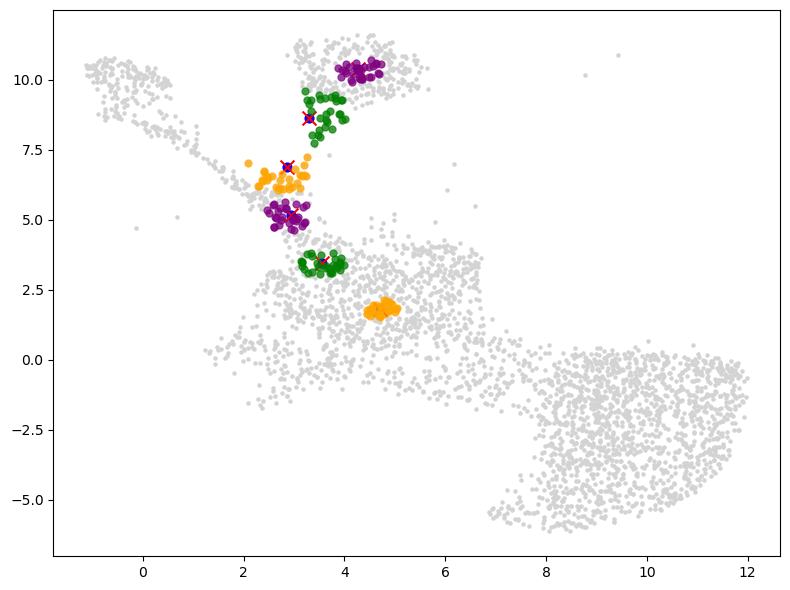

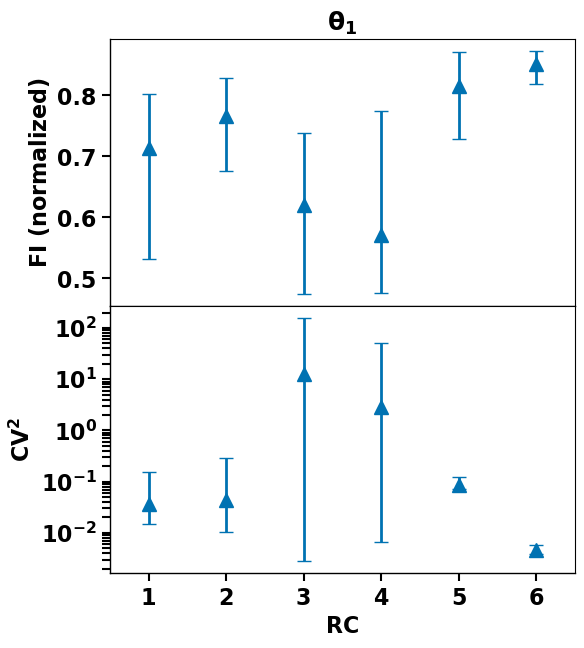

y: [3.5914838e-02 4.4705410e-02 1.2489765e+01 2.8374333e+00 8.7505050e-02
 4.7244430e-03]
max_vals: [1.53802708e-01 2.89515287e-01 1.53979019e+02 5.09296913e+01
 1.23995185e-01 5.68520464e-03]
min_vals: [0.01501629 0.01019914 0.00280528 0.00653942 0.07220998 0.0039185 ]
error: [[2.0898547e-02 3.4506269e-02 1.2486959e+01 2.8308940e+00 1.5295073e-02
  8.0594514e-04]
 [1.1788787e-01 2.4480988e-01 1.4148926e+02 4.8092258e+01 3.6490135e-02
  9.6076168e-04]]
y: [0.01337739 0.00195583 0.00959437 0.57739544 0.28320345 0.01220928]
max_vals: [3.0641926e-02 4.8018526e-03 3.7036005e-02 6.2986679e+00 2.7627597e+00
 1.6529696e-02]
min_vals: [0.00333502 0.00095748 0.00338143 0.00173772 0.07998649 0.00491806]
error: [[1.0042375e-02 9.9834939e-04 6.2129423e-03 5.7565773e-01 2.0321697e-01
  7.2912169e-03]
 [1.7264532e-02 2.8460270e-03 2.7441636e-02 5.7212725e+00 2.4795563e+00
  4.3204194e-03]]
y: [2.9104354  1.2895248  0.02133057 0.08757329 0.885322   0.5049518 ]
max_vals: [44.15811    20.595196    0.06

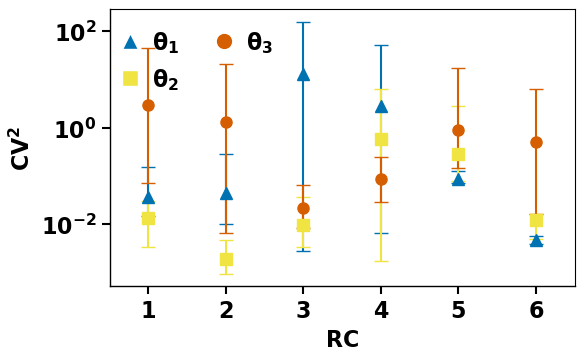

pca_svd_rc_mean_all:
[[[ -3.06135     -8.440883     3.651192  ]
  [ -3.923866    -8.411023    -3.1137834 ]
  [ -1.2947593   -9.019068     3.9611974 ]
  [ -2.036489    -9.286303     4.5772457 ]
  [ -3.3881838   -8.6489525    4.226599  ]
  [ -3.475812    -8.587703     4.0670533 ]
  [ -3.2383575   -7.759036     2.905891  ]
  [ -2.128754     9.0251      -0.5778429 ]
  [ -3.428064     8.940557    -2.5603282 ]
  [ -2.1136854   -8.789677     4.853644  ]
  [ -2.5081022   -7.9880066   -0.36589518]
  [ -3.9894125   -8.589733    -2.164717  ]
  [ -2.927961    -7.712799     2.759464  ]
  [ -3.9484491    8.032935    -2.7715428 ]
  [ -4.0600295    8.3486185    2.8306684 ]
  [ -2.8974204   -9.217229     1.7642392 ]
  [ -3.9461539   -9.492629     0.12263751]
  [ -3.4509609    9.515243    -2.001242  ]
  [ -4.358769     8.16192     -2.7359898 ]
  [ -3.4970899   -8.352384    -3.4961438 ]
  [ -2.8434865   -7.4801435    2.0251718 ]
  [ -2.6017451   -8.667367     3.7736852 ]
  [ -3.8113735    8.629654    -3.

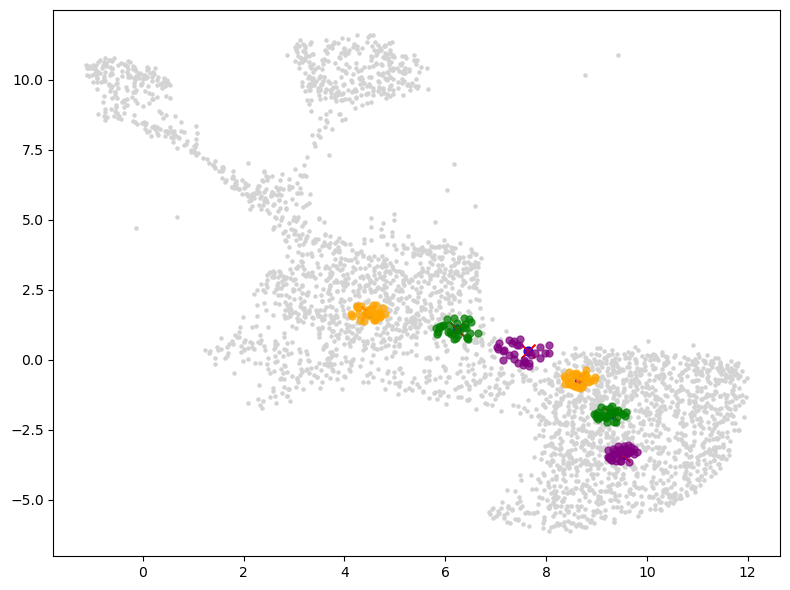

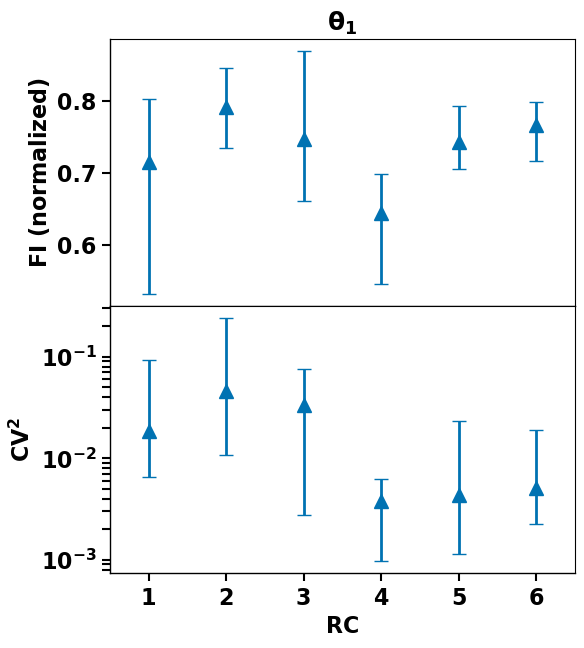

y: [0.01857379 0.04595508 0.03350573 0.00383453 0.00434134 0.00504074]
max_vals: [0.09227784 0.23880032 0.07491758 0.00631173 0.02344674 0.01895363]
min_vals: [0.00652997 0.01067734 0.00278506 0.00096974 0.00113743 0.00223911]
error: [[0.01204382 0.03527774 0.03072066 0.0028648  0.00320391 0.00280163]
 [0.07370405 0.19284524 0.04141185 0.0024772  0.0191054  0.01391289]]
y: [9.5368335e-03 1.0115058e-02 2.2746173e-01 4.7943501e+01 1.9564427e-02
 2.1636533e-02]
max_vals: [1.9180518e-02 1.5165982e-02 1.3316762e+00 1.4306262e+03 1.2378956e-01
 4.6284784e-02]
min_vals: [0.00576184 0.00564989 0.01738432 0.014062   0.00172563 0.00544181]
error: [[3.7749973e-03 4.4651693e-03 2.1007740e-01 4.7929440e+01 1.7838797e-02
  1.6194722e-02]
 [9.6436841e-03 5.0509237e-03 1.1042145e+00 1.3826827e+03 1.0422513e-01
  2.4648251e-02]]
y: [8.3471668e-01 3.9436014e+00 4.4796238e+00 1.8473670e-01 1.3360441e+05
 1.0725769e+00]
max_vals: [1.34401455e+01 9.51671753e+01 5.06554184e+01 5.40089965e-01
 4.00780100e+06

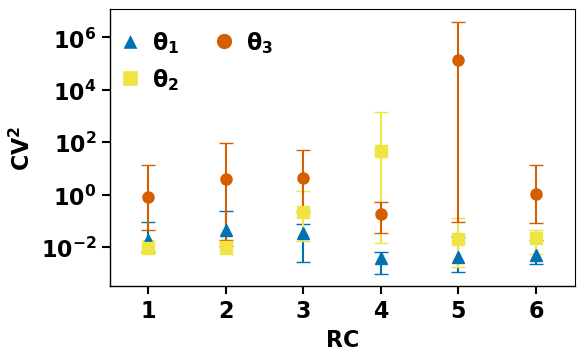

pca_svd_rc_mean_all:
[[[-3.91179752e+00  8.80571651e+00 -3.33265519e+00]
  [-3.42833352e+00 -8.62267971e+00  2.66994405e+00]
  [-2.15043116e+00 -9.03850079e+00  4.99376392e+00]
  [-4.52704000e+00  8.33395195e+00 -2.72506261e+00]
  [-3.64607215e+00  9.23770428e+00 -2.51862979e+00]
  [-3.68342471e+00 -8.69145107e+00 -4.06811523e+00]
  [-3.12787127e+00 -9.74824333e+00  1.62302780e+00]
  [-3.29826379e+00 -7.99206877e+00  2.98055959e+00]
  [-2.69152164e+00 -8.62858772e+00  2.52291369e+00]
  [-3.46034312e+00 -8.89983177e+00  4.24630642e+00]
  [-4.09903955e+00 -8.67957687e+00 -3.12824154e+00]
  [-4.10014725e+00 -9.74213505e+00  2.76597977e-01]
  [-2.72191715e+00 -8.68990040e+00  2.96010995e+00]
  [-4.05219460e+00  8.20104313e+00 -2.59844279e+00]
  [-2.65741634e+00  8.92958355e+00  2.91554499e+00]
  [-3.50467682e+00  9.43457603e+00 -1.90280068e+00]
  [-3.44284010e+00 -9.05225086e+00  2.59923506e+00]
  [-2.97597528e+00  8.47744465e+00  9.66896057e-01]
  [-3.31997156e+00 -8.49994755e+00  1.66530

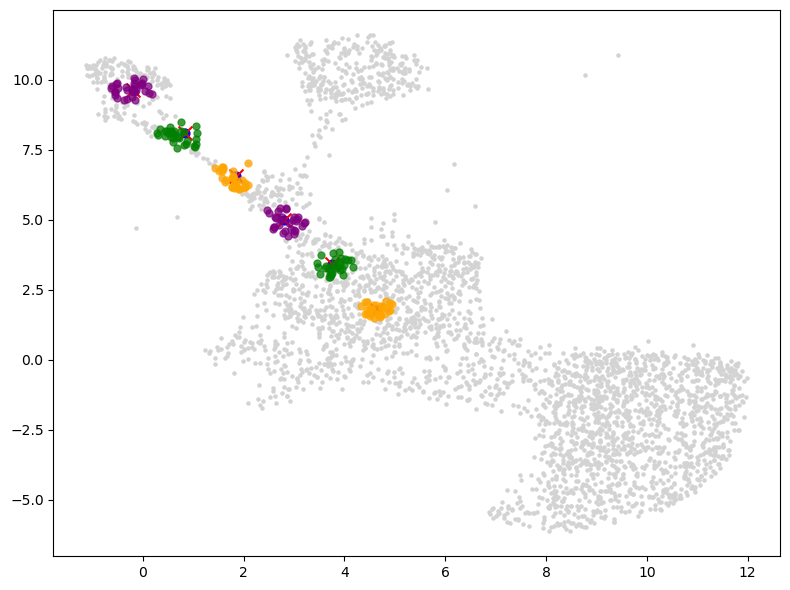

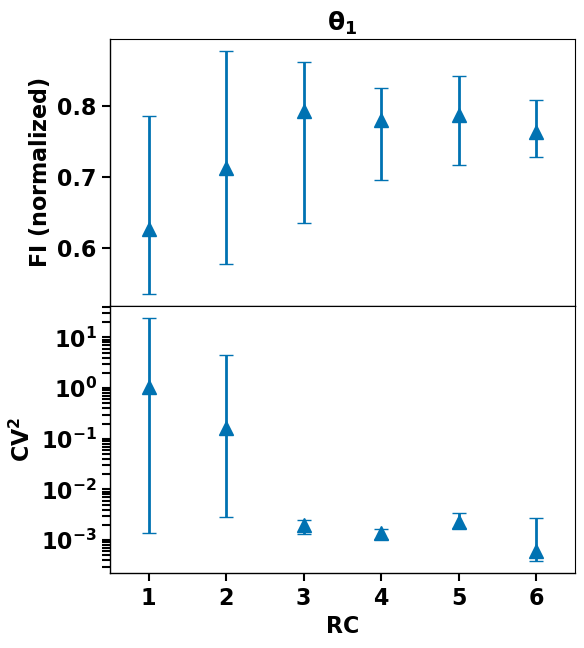

y: [1.0416515e+00 1.6473848e-01 1.9670813e-03 1.3835877e-03 2.2974417e-03
 6.2232552e-04]
max_vals: [2.3791374e+01 4.4432769e+00 2.5157342e-03 1.6386101e-03 3.4584785e-03
 2.6881425e-03]
min_vals: [0.00141265 0.00291838 0.0013248  0.00104266 0.00170528 0.00038603]
error: [[1.0402389e+00 1.6182010e-01 6.4228079e-04 3.4092995e-04 5.9216097e-04
  2.3629444e-04]
 [2.2749723e+01 4.2785382e+00 5.4865284e-04 2.5502243e-04 1.1610368e-03
  2.0658169e-03]]
y: [0.05895461 0.00145744 0.0183121  0.04736876 0.13925189 0.32373717]
max_vals: [1.6692787e+00 2.9062533e-03 2.5696531e-02 8.5790209e-02 4.9139193e-01
 4.2589321e+00]
min_vals: [0.00150071 0.00079464 0.0157137  0.02811801 0.01868373 0.01771409]
error: [[5.74538969e-02 6.62802369e-04 2.59840488e-03 1.92507468e-02
  1.20568156e-01 3.06023091e-01]
 [1.61032414e+00 1.44881359e-03 7.38442875e-03 3.84214520e-02
  3.52140039e-01 3.93519497e+00]]
y: [7.7397676  0.8315368  0.01777207 0.01561119 0.03287913 1.0184089 ]
max_vals: [1.9437241e+02 1.4944738

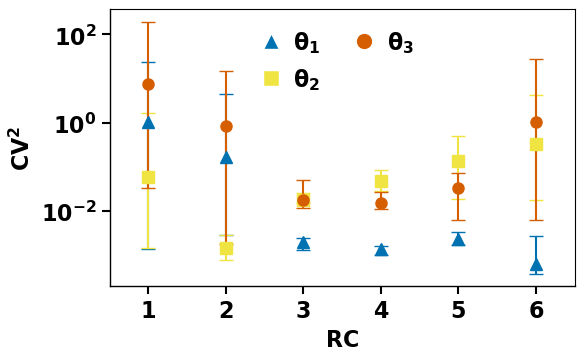

pca_svd_rc_mean_all:
[[[  4.819534   -13.265082     0.90077853]
  [  4.0467124  -12.765614    -1.4077525 ]
  [ -3.477507   -12.871636    -3.068296  ]
  [  6.3375483   10.375935    -2.08684   ]
  [  5.5737576  -11.343406    -3.1966627 ]
  [ -3.7765365  -12.7918415   -3.1308162 ]
  [  5.5988507   13.222239     0.30327293]
  [  7.147431   -11.379558    -4.189397  ]
  [ 14.518513     0.37756217   1.1826905 ]
  [ -0.08933511 -13.934476    -0.88559616]
  [  5.2339625   12.883862     1.3101094 ]
  [  4.8444886  -12.86666     -0.41595498]
  [  0.4890105   14.620217     0.79853475]
  [ -2.6631598  -13.066393    -2.8323696 ]
  [  4.720401   -13.273996     0.33922094]
  [  5.8273745  -13.136141    -0.0940971 ]
  [ 12.822832     6.0769873   -0.10966161]
  [  4.650649   -12.899456    -0.60148406]
  [ -0.62543553 -13.321666    -2.7578883 ]
  [  4.922705    13.559539    -1.0815212 ]
  [ -2.400915   -13.112784    -2.7137446 ]
  [  2.7434175  -12.939925     2.76294   ]
  [  6.3998713  -10.571872    -3.

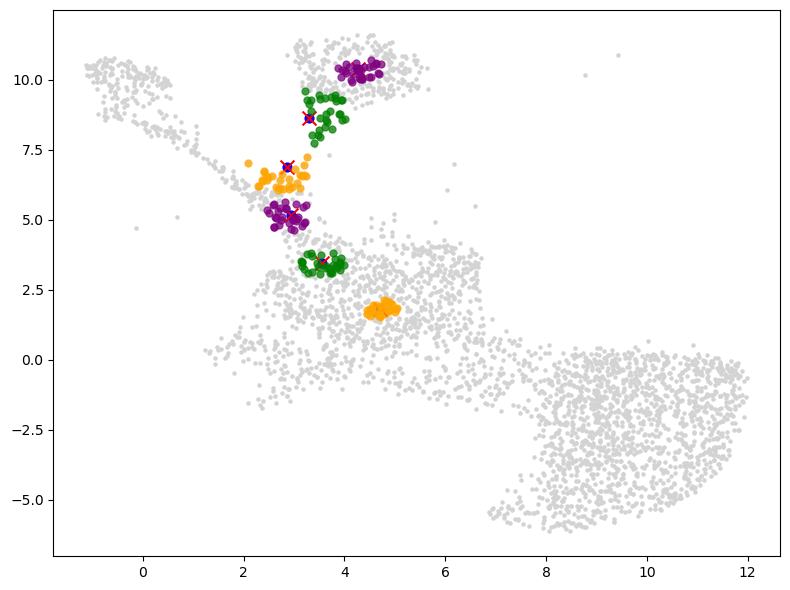

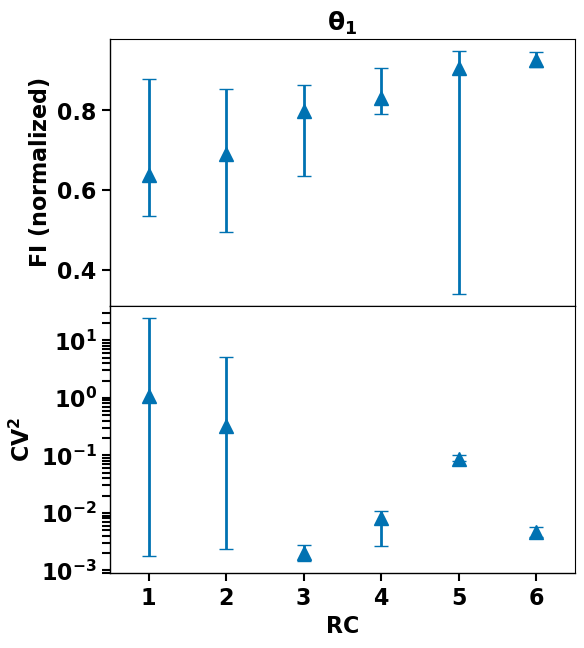

y: [1.0671291  0.32307914 0.00201228 0.00809612 0.08720518 0.00461075]
max_vals: [2.4057301e+01 5.2037134e+00 2.7219520e-03 1.0620104e-02 9.9536143e-02
 5.5926926e-03]
min_vals: [0.0018169  0.00235049 0.00145243 0.00270556 0.0810893  0.00388234]
error: [[1.0653123e+00 3.2072866e-01 5.5985118e-04 5.3905612e-03 6.1158836e-03
  7.2840508e-04]
 [2.2990171e+01 4.8806343e+00 7.0967013e-04 2.5239810e-03 1.2330964e-02
  9.8194415e-04]]
y: [0.09021993 0.0012774  0.01847591 0.8322393  0.4335903  1.1581298 ]
max_vals: [2.5771234e+00 2.9743405e-03 2.6924390e-02 1.0018811e+01 3.0876789e+00
 2.9917471e+01]
min_vals: [0.00218554 0.00054183 0.01591142 0.09111131 0.13734324 0.03689727]
error: [[8.8034391e-02 7.3556567e-04 2.5644936e-03 7.4112797e-01 2.9624707e-01
  1.1212325e+00]
 [2.4869034e+00 1.6969433e-03 8.4484778e-03 9.1865721e+00 2.6540885e+00
  2.8759340e+01]]
y: [2.7764418  1.6463119  0.02742899 0.18567982 2.307368   0.5918278 ]
max_vals: [38.11913    34.529984    0.138162    0.28034732 50.030

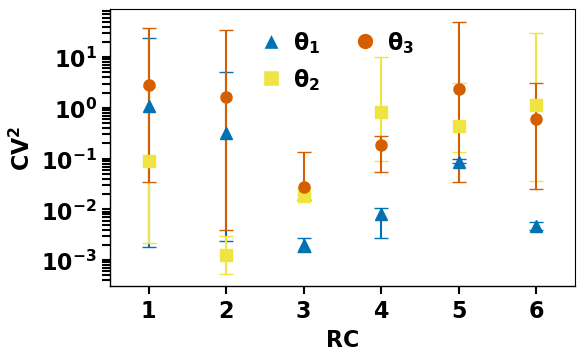

pca_svd_rc_mean_all:
[[[  5.5265017  -11.201538    -3.2182553 ]
  [  4.736959   -13.12291      0.9334413 ]
  [  7.0701632  -11.263149    -4.194363  ]
  [ 14.395245     0.33983237   1.06065   ]
  [ -3.4638872  -12.721019    -3.0717285 ]
  [ -2.6506777  -12.91822     -2.8413475 ]
  [  3.9820707  -12.637488    -1.4349744 ]
  [ -0.09572339 -13.79768     -0.93547606]
  [  6.2969      10.260129    -2.1765244 ]
  [ -3.7595031  -12.641455    -3.1332355 ]
  [  4.8575654   13.413442    -1.1122515 ]
  [ -0.6466675  -13.157101    -2.7617953 ]
  [  5.760722   -12.990971    -0.06737285]
  [  4.768297   -12.737941    -0.38923877]
  [  5.1579547   12.751919     1.3319519 ]
  [  5.500913    13.081944     0.3938592 ]
  [  0.4804434   14.490825     0.8204985 ]
  [ 12.711298     6.0020814   -0.30211788]
  [  4.65035    -13.139738     0.3509885 ]
  [  2.7377837  -12.790254     2.7583666 ]
  [ -0.4542664  -12.461088    -2.92629   ]
  [  6.3231006  -10.985076     2.5560548 ]
  [  4.577935   -12.768706    -0.

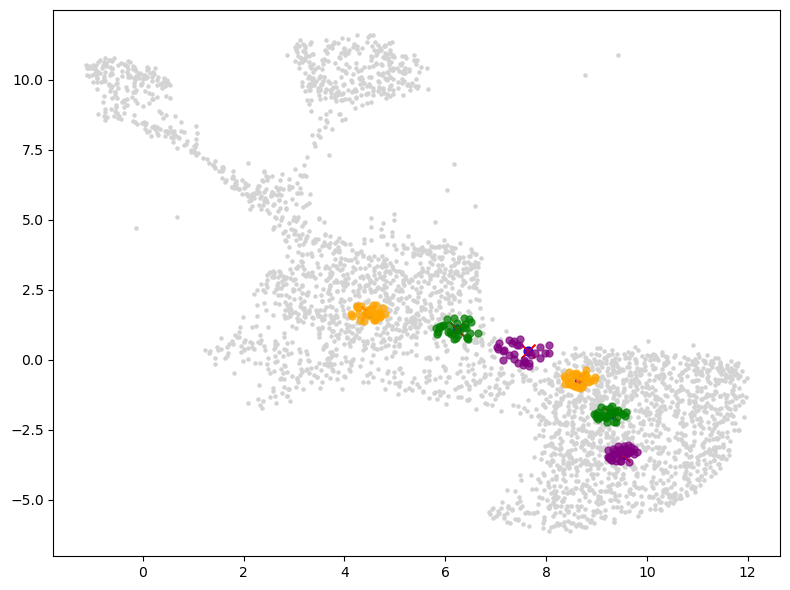

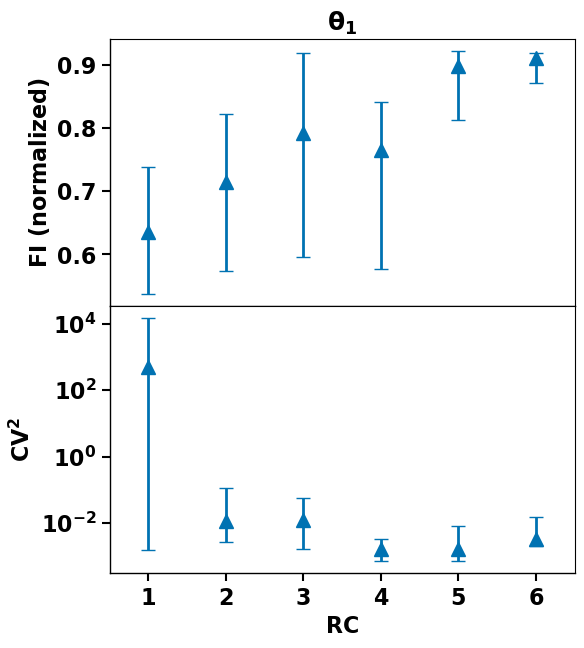

y: [4.7796359e+02 1.1547135e-02 1.2050169e-02 1.6082973e-03 1.6472723e-03
 3.3987062e-03]
max_vals: [1.4337419e+04 1.1401275e-01 5.5366095e-02 3.2260404e-03 8.3681606e-03
 1.5373928e-02]
min_vals: [0.00150916 0.00266776 0.00166128 0.00071228 0.00072159 0.0020192 ]
error: [[4.77962097e+02 8.87937285e-03 1.03888912e-02 8.96018406e-04
  9.25687200e-04 1.37950759e-03]
 [1.38594551e+04 1.02465615e-01 4.33159247e-02 1.61774305e-03
  6.72088843e-03 1.19752213e-02]]
y: [2.99132313e-03 1.48631074e-02 8.74693108e+00 9.00882408e-02
 2.96107221e+00 1.00396186e-01]
max_vals: [5.0820126e-03 2.8249126e-02 8.5701492e+01 5.5493361e-01 3.2749748e+01
 1.5239099e-01]
min_vals: [0.00117184 0.00930965 0.10008369 0.02677912 0.09035921 0.06703456]
error: [[1.8194856e-03 5.5534616e-03 8.6468477e+00 6.3309126e-02 2.8707130e+00
  3.3361621e-02]
 [2.0906895e-03 1.3386019e-02 7.6954559e+01 4.6484536e-01 2.9788675e+01
  5.1994801e-02]]
y: [2.5144207e+00 2.9134976e+02 2.7000867e+02 3.4752139e+03 1.0615600e+00
 1.335

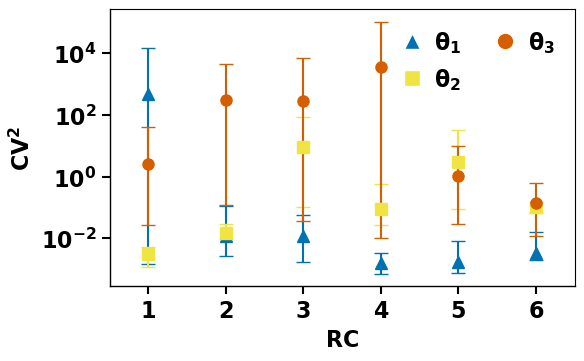

pca_svd_rc_mean_all:
[[[ 4.77833652e+00 -1.29821510e+01 -7.28648245e-01]
  [ 6.38592434e+00 -1.07464857e+01 -3.69666839e+00]
  [-3.71335769e+00 -1.29572735e+01 -2.90139437e+00]
  [ 4.84148073e+00 -1.33676920e+01  2.47233316e-01]
  [ 6.29136801e+00  1.05354357e+01 -1.63563883e+00]
  [-2.33236337e+00 -1.32534275e+01 -2.49926543e+00]
  [ 5.77929878e+00  1.33644686e+01  1.01594783e-01]
  [ 4.16356802e+00 -1.28638916e+01 -1.15367424e+00]
  [ 2.67126799e+00 -1.27737455e+01  2.22843242e+00]
  [-3.41119075e+00 -1.30353489e+01 -2.83860302e+00]
  [ 4.96350002e+00 -1.34044371e+01  7.77096510e-01]
  [ 5.65888464e-01  1.47122974e+01  5.53033650e-01]
  [ 3.51549959e+00 -1.32531786e+01  1.49368203e+00]
  [ 4.97593689e+00 -1.29457645e+01 -5.25991678e-01]
  [ 5.87337446e+00 -1.30711584e+01 -2.10361004e+00]
  [ 1.28065510e+01  6.15361071e+00  2.62879997e-01]
  [ 3.58236861e+00 -1.31652794e+01  3.25799823e+00]
  [ 5.87122583e+00 -1.39353991e+01  8.39520752e-01]
  [-1.74796879e+00 -1.23187599e+01 -3.44400

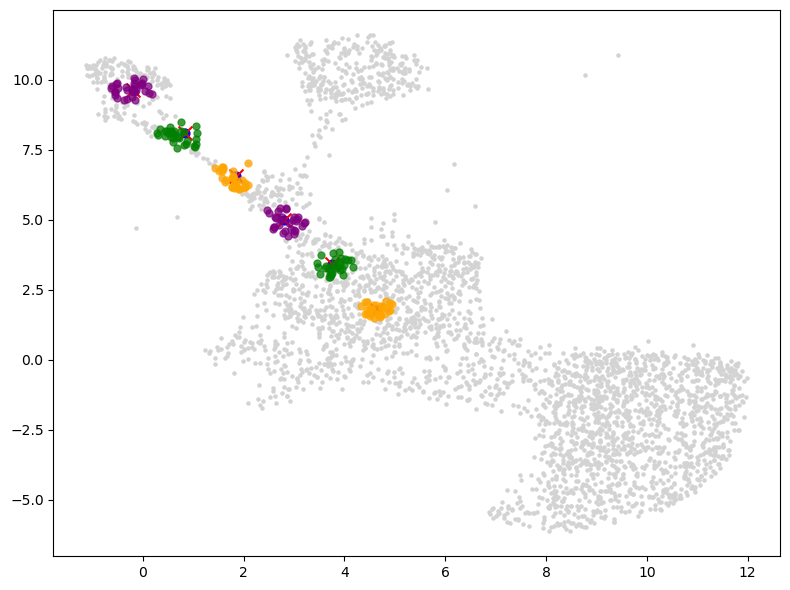

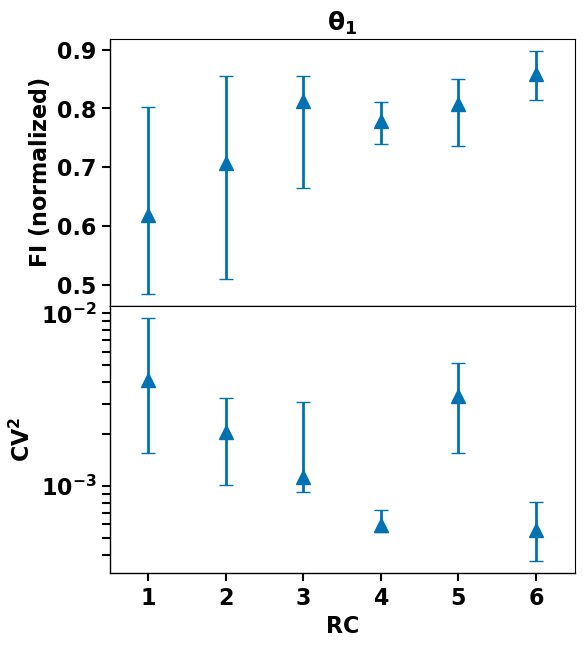

y: [0.00413818 0.00204714 0.00113385 0.00059802 0.00332574 0.00055634]
max_vals: [0.00935973 0.00324155 0.0030767  0.00073001 0.00516159 0.00080385]
min_vals: [0.00154886 0.0010186  0.00091806 0.00054193 0.00155558 0.00036693]
error: [[2.5893194e-03 1.0285403e-03 2.1578965e-04 5.6083081e-05 1.7701605e-03
  1.8941317e-04]
 [5.2215508e-03 1.1944170e-03 1.9428523e-03 1.3198977e-04 1.8358557e-03
  2.4751190e-04]]
y: [1.05755895e-01 1.73778462e+00 3.00036743e-02 5.58737181e-02
 1.07713672e+03 2.69068408e+00]
max_vals: [2.0111601e+00 5.1799477e+01 8.2434170e-02 7.5420856e-02 1.1309001e+04
 2.7388317e+01]
min_vals: [0.00189068 0.0015226  0.02353857 0.04472797 0.5646523  0.0862811 ]
error: [[1.0386522e-01 1.7362621e+00 6.4651053e-03 1.1145748e-02 1.0765720e+03
  2.6044030e+00]
 [1.9054042e+00 5.0061691e+01 5.2430496e-02 1.9547138e-02 1.0231864e+04
  2.4697634e+01]]
y: [7.8939447  0.39878228 0.5947533  0.13163169 3.9060435  0.06023829]
max_vals: [30.49101     5.61105    15.584906    2.5291378  

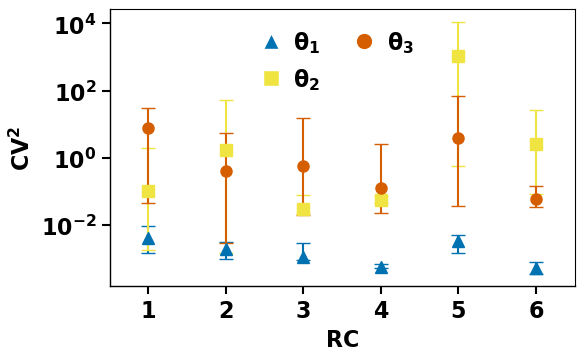

pca_svd_rc_mean_all:
[[[ 7.18152475e+00  1.17949705e+01  1.09456062e+00]
  [ 8.45480537e+00  1.09639797e+01  1.57554701e-01]
  [ 1.29078197e+01  2.25994968e+00  2.59568870e-01]
  [ 1.17550917e+01 -7.01908207e+00 -3.19624305e-01]
  [ 1.32898216e+01  2.97901869e+00  1.71464577e-01]
  [ 1.26610041e+01  2.76213741e+00 -1.39318898e-01]
  [ 8.37989140e+00 -1.15938396e+01  7.52686143e-01]
  [ 1.04112444e+01 -9.10791874e+00  3.95907581e-01]
  [ 1.39843102e+01 -3.86250496e-01 -3.00837815e-01]
  [ 8.46796989e+00  1.16124258e+01  6.09132111e-01]
  [-7.43842649e+00 -1.16793823e+01  1.14138377e+00]
  [ 8.18505859e+00  1.12476683e+01  1.54752529e+00]
  [-9.30670166e+00  1.12733831e+01  5.87175906e-01]
  [ 1.35293760e+01 -1.62395608e+00 -2.13803530e-01]
  [ 1.06003418e+01  8.69647884e+00  1.70402825e-01]
  [ 8.28376865e+00  1.16386595e+01 -2.56771684e-01]
  [ 1.37893257e+01  2.95047641e+00  2.37311706e-01]
  [ 8.02788448e+00  1.13561039e+01  1.56738436e+00]
  [ 1.12963724e+01 -7.99518061e+00 -4.89641

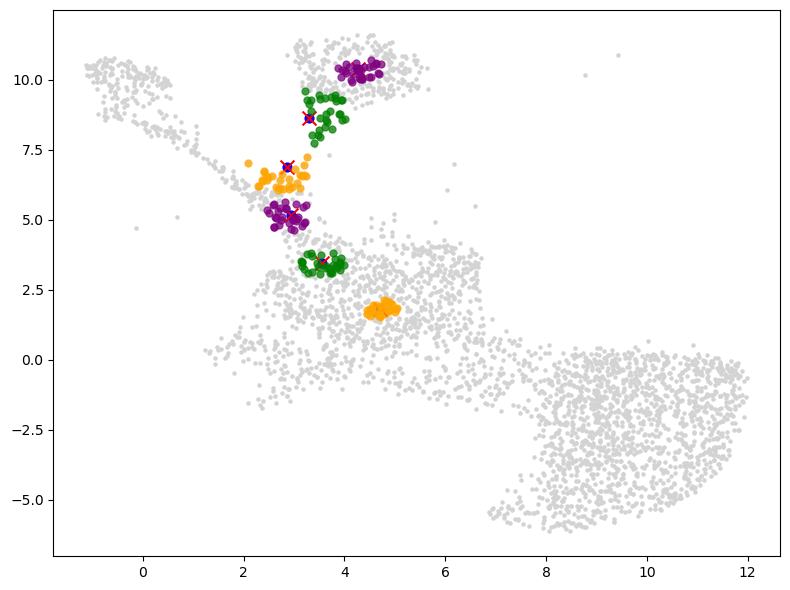

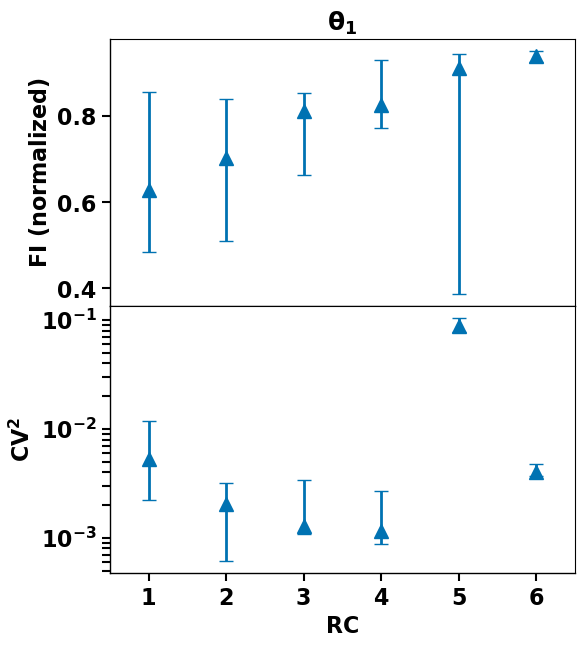

y: [0.00531422 0.00203529 0.00129284 0.00115704 0.08793652 0.00406025]
max_vals: [0.01183571 0.00320504 0.00338176 0.00267442 0.10372876 0.00473807]
min_vals: [0.00224571 0.00061177 0.00107522 0.00088613 0.07744172 0.00368877]
error: [[0.00306851 0.00142352 0.00021762 0.00027091 0.0104948  0.00037149]
 [0.00652149 0.00116976 0.00208892 0.00151737 0.01579224 0.00067782]]
y: [0.09697012 1.6734761  0.03169691 0.54523444 0.21070299 2.4348028 ]
max_vals: [ 2.3791447  50.074448    0.08978508  0.7717614   0.31487736 32.0117    ]
min_vals: [0.00195889 0.00166766 0.02658887 0.14430799 0.1003149  0.03039258]
error: [[9.50112268e-02 1.67180848e+00 5.10803424e-03 4.00926471e-01
  1.10388085e-01 2.40441012e+00]
 [2.28217459e+00 4.84009705e+01 5.80881760e-02 2.26526976e-01
  1.04174376e-01 2.95768967e+01]]
y: [2.0220655e+01 7.1103805e-01 8.1708282e-02 3.1259078e-01 1.3535920e+00
 2.9543732e+02]
max_vals: [3.1469199e+02 1.3231155e+01 5.7486629e-01 1.4628069e+00 1.0474680e+01
 8.3547451e+03]
min_vals:

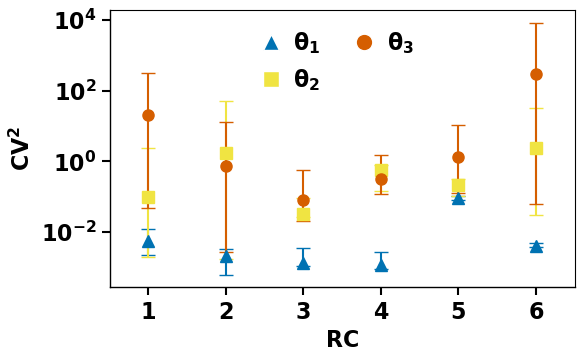

pca_svd_rc_mean_all:
[[[ 1.31522217e+01  2.94961190e+00  1.41592190e-01]
  [ 7.07868528e+00  1.16720333e+01  1.08778203e+00]
  [ 1.03224487e+01 -9.08117485e+00  3.86150897e-01]
  [ 1.38773403e+01 -3.57080489e-01 -2.82979935e-01]
  [ 1.27668123e+01  2.23726583e+00  2.85482526e-01]
  [ 1.33896885e+01 -1.60870099e+00 -1.83709294e-01]
  [ 8.35963345e+00  1.08459215e+01  1.81879237e-01]
  [ 8.37673855e+00  1.14923162e+01  6.29983902e-01]
  [ 1.16523800e+01 -6.95655203e+00 -3.53285968e-01]
  [ 1.25237331e+01  2.73128796e+00 -1.03917174e-01]
  [ 8.63092518e+00  1.08138666e+01  1.66135460e-01]
  [ 1.11830473e+01 -7.90016890e+00 -5.44957936e-01]
  [ 8.18035984e+00  1.15076332e+01 -2.35870764e-01]
  [ 8.09230232e+00  1.11292200e+01  1.54162097e+00]
  [-7.34539986e+00 -1.15582228e+01  1.14033127e+00]
  [ 8.25460529e+00 -1.14528608e+01  7.52999365e-01]
  [-9.22721767e+00  1.11813374e+01  6.16294861e-01]
  [ 1.36928749e+01  2.94098949e+00  2.56495178e-01]
  [ 1.04761257e+01  8.60904217e+00  1.72758

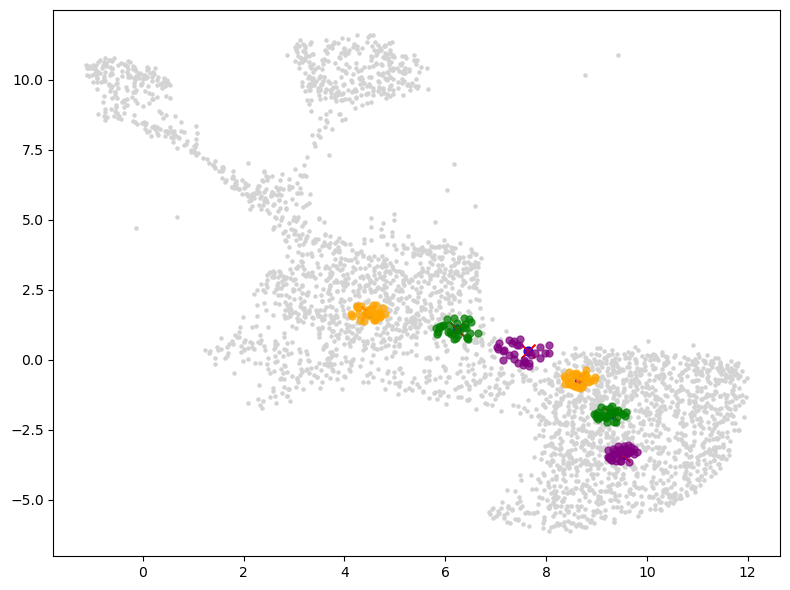

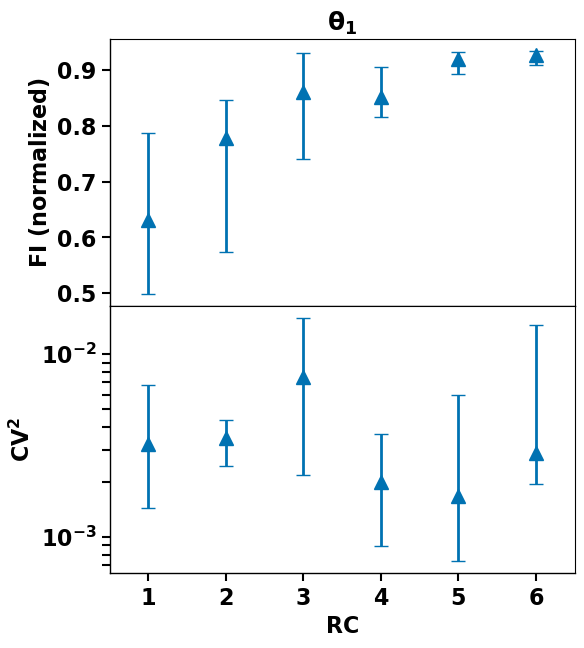

y: [0.00320588 0.00347406 0.00752285 0.00200345 0.0016785  0.00288795]
max_vals: [0.00675527 0.00438091 0.0156991  0.00366402 0.00599647 0.01449432]
min_vals: [0.00144235 0.00243611 0.00219564 0.00088746 0.00073739 0.00195446]
error: [[0.00176352 0.00103795 0.00532722 0.00111599 0.00094111 0.00093348]
 [0.00354939 0.00090685 0.00817625 0.00166057 0.00431797 0.01160638]]
y: [2.8387683e-02 2.0628246e-02 2.3125477e+01 2.8939547e-02 2.0734219e+01
 6.5336868e-02]
max_vals: [5.3697485e-01 4.0246412e-02 6.4426202e+02 5.4039184e-02 4.0344467e+02
 2.5834590e-01]
min_vals: [0.00201761 0.01648126 0.20992292 0.01779266 0.05452662 0.02856323]
error: [[2.6370073e-02 4.1469857e-03 2.2915554e+01 1.1146886e-02 2.0679691e+01
  3.6773637e-02]
 [5.0858718e-01 1.9618167e-02 6.2113654e+02 2.5099637e-02 3.8271045e+02
  1.9300903e-01]]
y: [19.367878   25.282671    2.2577536   5.4865694  10.102746    0.33946958]
max_vals: [329.75806  524.7272    36.797283  71.197105 271.75616    6.749545]
min_vals: [0.02849477

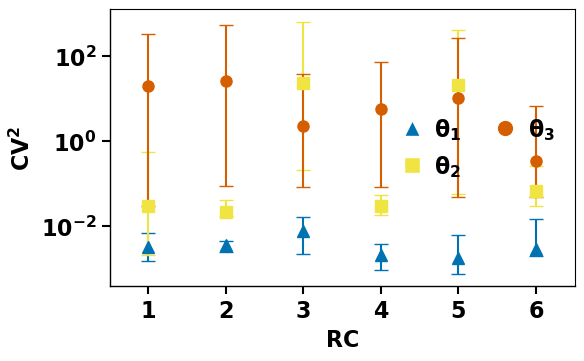

pca_svd_rc_mean_all:
[[[ 8.17041969e+00  1.13885746e+01  1.49164891e+00]
  [ 1.25208826e+01 -5.27203226e+00 -1.30678022e+00]
  [ 1.27667665e+01  2.87519026e+00 -2.74228960e-01]
  [ 1.07687616e+01  8.67683220e+00  1.79545701e-01]
  [ 1.17713909e+01 -7.17846823e+00 -1.60383150e-01]
  [ 1.16740513e+01  6.29497242e+00 -3.86658669e-01]
  [ 8.59883690e+00 -1.16757870e+01  7.09995806e-01]
  [ 8.61143970e+00  1.10077953e+01  3.07281744e-02]
  [ 9.14169502e+00  9.81123352e+00  4.02053714e-01]
  [ 1.30444231e+01  2.19723678e+00  1.45157352e-01]
  [ 7.36228848e+00  1.18284397e+01  1.08782113e+00]
  [-9.41439915e+00  1.12495947e+01  4.92670566e-01]
  [ 8.83863449e+00  1.08211613e+01  8.25183690e-02]
  [ 8.32793617e+00  1.12781944e+01  1.47402799e+00]
  [ 9.84881210e+00  1.01556339e+01  3.17038178e-01]
  [ 1.36674767e+01  2.90381765e+00  3.04694384e-01]
  [ 1.34645166e+01 -7.79591620e-01  1.30316246e+00]
  [ 9.11345768e+00  1.07172794e+01  5.18676817e-01]
  [ 1.10316505e+01  7.59511232e+00  3.17037

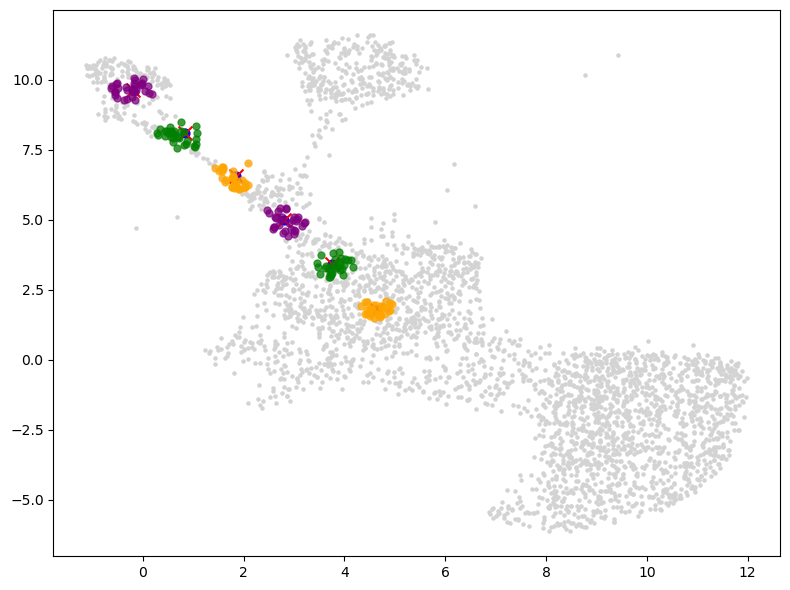

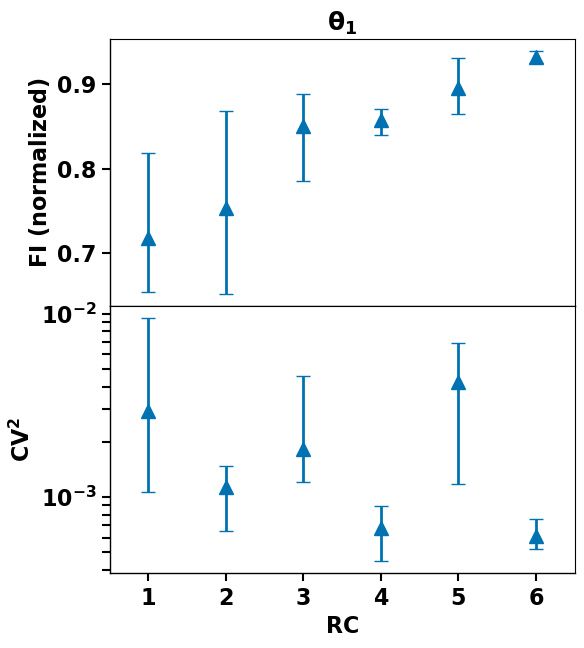

y: [0.00292361 0.00112893 0.00181446 0.00067895 0.00424989 0.00061102]
max_vals: [0.00941631 0.00147713 0.00458795 0.00089279 0.00692006 0.0007604 ]
min_vals: [0.00106449 0.00064745 0.00120959 0.00044615 0.00118051 0.00051795]
error: [[1.8591204e-03 4.8147724e-04 6.0486759e-04 2.3280416e-04 3.0693761e-03
  9.3065493e-05]
 [6.4926976e-03 3.4820754e-04 2.7734931e-03 2.1383661e-04 2.6701726e-03
  1.4937972e-04]]
y: [2.8500226e-01 6.6668391e-01 3.8463020e-01 4.1624612e+02 1.1413788e+00
 1.5483339e+00]
max_vals: [3.9407020e+00 1.7340214e+01 5.9512396e+00 9.2874326e+03 8.6440706e+00
 1.9466663e+01]
min_vals: [0.00394866 0.00304601 0.07548188 0.45714048 0.04842125 0.15292542]
error: [[2.8105360e-01 6.6363788e-01 3.0914831e-01 4.1578897e+02 1.0929575e+00
  1.3954085e+00]
 [3.6556997e+00 1.6673531e+01 5.5666094e+00 8.8711865e+03 7.5026917e+00
  1.7918329e+01]]
y: [3.5680088e+01 1.5402801e+00 3.3987785e+01 3.5516989e+02 1.4631903e+02
 4.3641653e-02]
max_vals: [6.2996710e+02 1.8632288e+01 7.41139

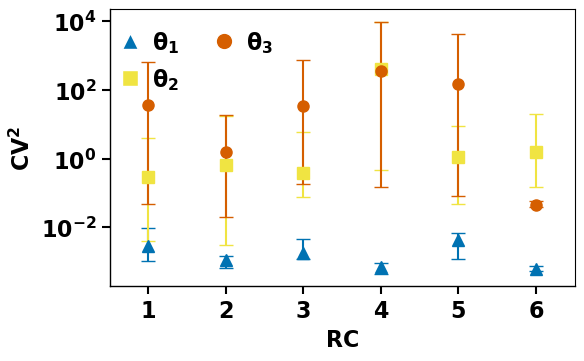

pca_svd_rc_mean_all:
[[[ 1.21786470e+01  7.04895210e+00 -1.30618024e+00]
  [ 1.19271107e+01  6.61033583e+00 -4.78922874e-02]
  [ 1.25979433e+01  3.04735684e+00 -1.39248684e-01]
  [ 1.35475702e+01  1.27468598e+00 -2.73393899e-01]
  [ 1.29976492e+01  2.33731627e+00  6.56091273e-01]
  [ 1.31139069e+01 -1.80640721e+00  9.07600820e-01]
  [ 1.17961617e+01  8.64324570e+00  1.15080245e-01]
  [ 1.20417576e+01 -4.33707857e+00 -7.23685503e-01]
  [ 1.45881834e+01 -3.94499111e+00  2.62658310e+00]
  [ 1.32263308e+01  4.19252777e+00 -4.58214208e-02]
  [ 1.24181118e+01  6.78504944e+00 -1.07808006e+00]
  [ 1.18077431e+01  7.10730076e+00 -1.71904624e-01]
  [ 1.45999165e+01 -2.88558078e+00 -2.12632671e-01]
  [ 1.31306095e+01  1.15756071e+00  1.77495256e-01]
  [ 1.25831127e+01  4.79652309e+00 -1.16804205e-01]
  [ 1.10034370e+01  8.43716812e+00  2.03856885e-01]
  [ 1.34288340e+01  4.26278114e+00  2.49891329e+00]
  [ 1.17453156e+01  7.36955118e+00 -1.00162812e-01]
  [ 1.45979309e+01  2.89607501e+00  8.53973

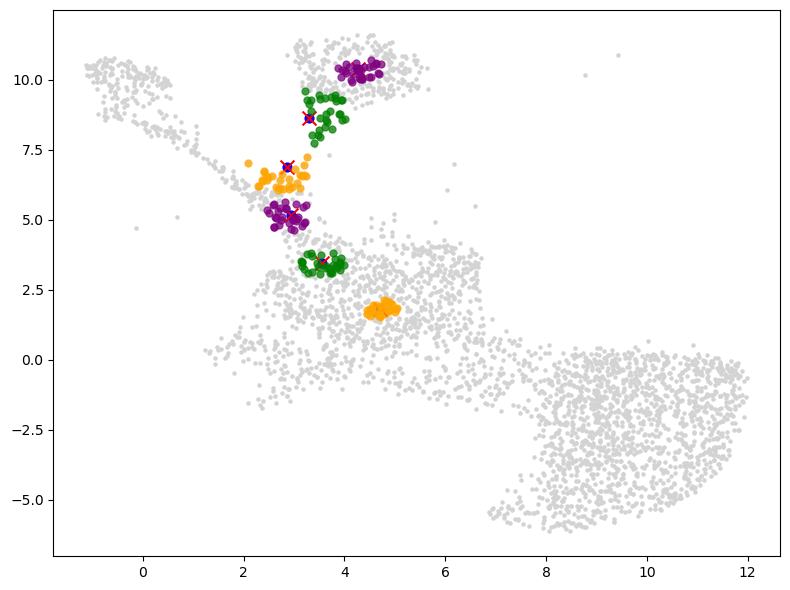

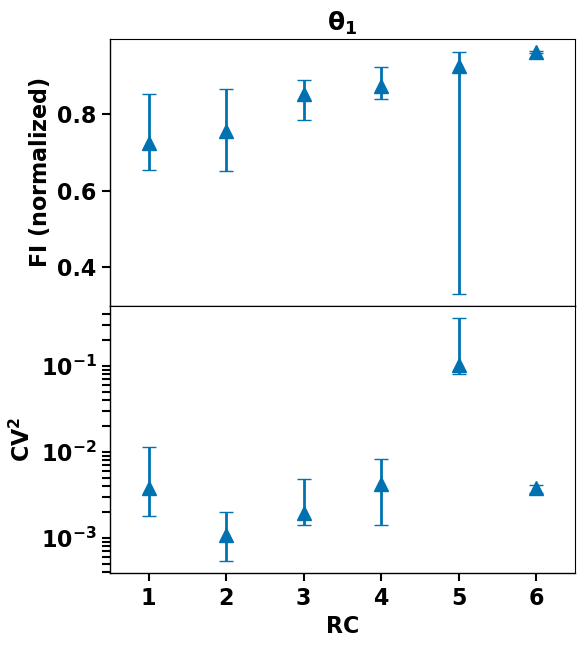

y: [0.00382506 0.00108645 0.00196124 0.00426335 0.10218714 0.00376387]
max_vals: [0.01143506 0.0019874  0.00484647 0.00832325 0.35820174 0.00414398]
min_vals: [0.00180374 0.00053371 0.00142266 0.00139987 0.08044759 0.00329526]
error: [[0.00202132 0.00055275 0.00053858 0.00286347 0.02173955 0.00046861]
 [0.00761    0.00090094 0.00288523 0.0040599  0.2560146  0.00038011]]
y: [7.4532419e-01 2.1157873e+00 3.1377891e-01 5.3912012e+03 2.9987509e+01
 9.1525948e-01]
max_vals: [1.6320070e+01 3.5117722e+01 3.1728332e+00 1.5490084e+05 3.4708701e+02
 1.2979434e+01]
min_vals: [0.00378984 0.00399183 0.0780251  0.5881154  0.08241947 0.03763921]
error: [[7.4153435e-01 2.1117954e+00 2.3575380e-01 5.3906133e+03 2.9905088e+01
  8.7762028e-01]
 [1.5574746e+01 3.3001934e+01 2.8590543e+00 1.4950964e+05 3.1709949e+02
  1.2064175e+01]]
y: [ 76.927895    1.3777425  56.181923  235.60188     1.083672    3.2956169]
max_vals: [1202.144      17.020363  882.0807   4613.2007      9.83111    47.197098]
min_vals: [0.05

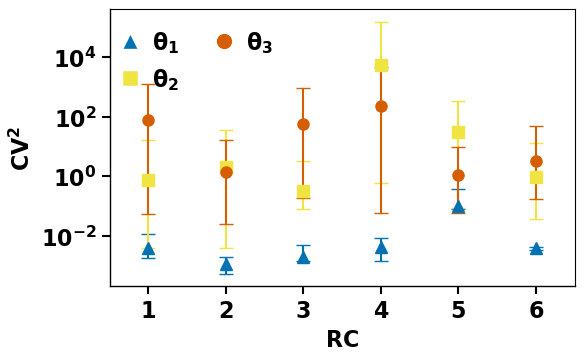

pca_svd_rc_mean_all:
[[[ 1.28820381e+01  2.30606127e+00  6.55485451e-01]
  [ 1.20169563e+01  6.98388672e+00 -1.26041651e+00]
  [ 1.19342108e+01 -4.28130388e+00 -6.90238297e-01]
  [ 1.44578524e+01 -3.82939553e+00  2.55104494e+00]
  [ 1.24657202e+01  3.02436757e+00 -1.27555236e-01]
  [ 1.30023098e+01  1.15037274e+00  1.82761222e-01]
  [ 1.17964430e+01  6.55152082e+00 -3.02389208e-02]
  [ 1.30973091e+01  4.17070484e+00 -2.33051497e-02]
  [ 1.33957624e+01  1.22158170e+00 -3.01307023e-01]
  [ 1.30011454e+01 -1.79140115e+00  9.04658020e-01]
  [ 1.24075880e+01  3.32751632e+00 -1.50977418e-01]
  [ 1.44336395e+01  2.83964825e+00  4.80600558e-02]
  [ 1.08905525e+01  8.37705040e+00  2.16276392e-01]
  [ 1.16816130e+01  7.04497194e+00 -1.62635326e-01]
  [ 1.22584667e+01  6.72938633e+00 -1.04761803e+00]
  [ 1.16160059e+01  8.54461861e+00  1.14798263e-01]
  [ 1.44566650e+01 -2.87092471e+00 -2.01227248e-01]
  [ 1.33372107e+01  4.19002056e+00  2.44240403e+00]
  [ 1.24365139e+01  4.76308107e+00 -1.32033

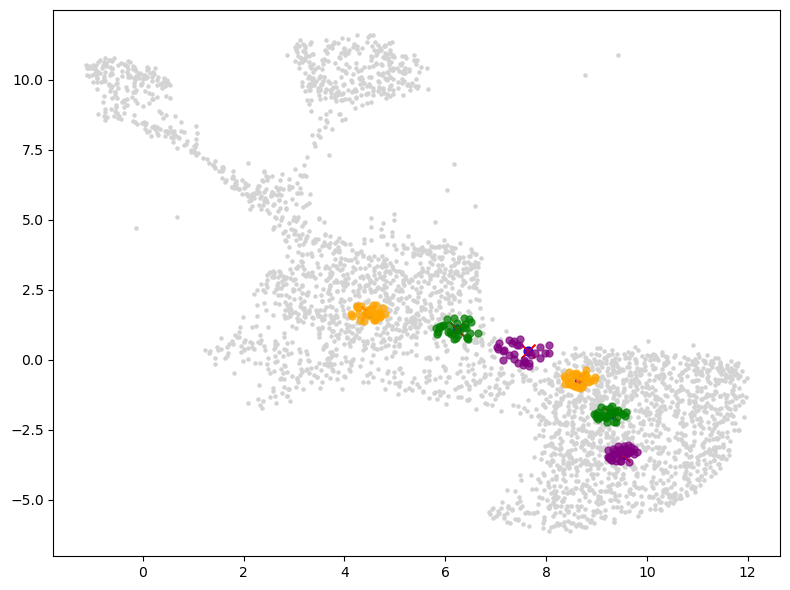

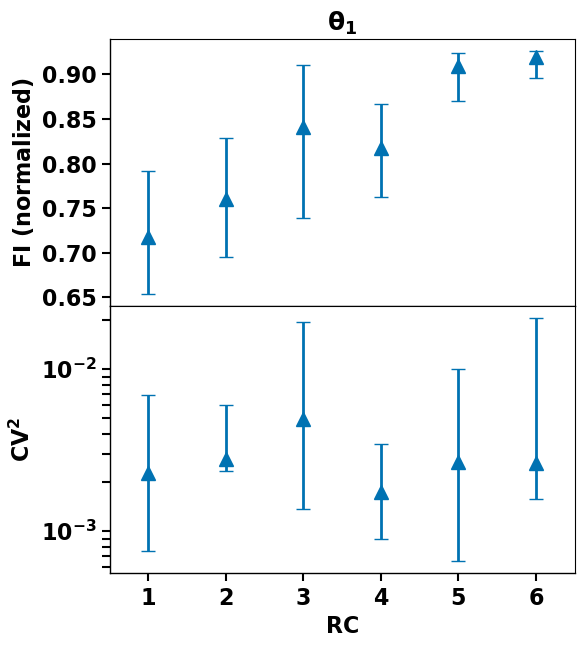

y: [0.00227112 0.00278532 0.0049554  0.00174384 0.00265773 0.00264878]
max_vals: [0.00691915 0.00596967 0.01942913 0.00343674 0.01006255 0.0205867 ]
min_vals: [0.00074823 0.00235111 0.00137228 0.00089829 0.00065252 0.00156962]
error: [[0.00152289 0.0004342  0.00358312 0.00084555 0.00200522 0.00107916]
 [0.00464804 0.00318436 0.01447374 0.0016929  0.00740481 0.01793792]]
y: [ 0.1036177   0.09822892 32.7256      0.11056875  0.13583997  0.06282812]
max_vals: [2.1421118e+00 1.4710646e+00 3.1028101e+02 2.7645791e-01 5.6796271e-01
 8.5606456e-02]
min_vals: [0.00466461 0.02415365 0.02777076 0.04414451 0.00789606 0.03291422]
error: [[9.8953091e-02 7.4075267e-02 3.2697830e+01 6.6424236e-02 1.2794390e-01
  2.9913899e-02]
 [2.0384941e+00 1.3728356e+00 2.7755542e+02 1.6588916e-01 4.3212274e-01
  2.2778340e-02]]
y: [2.1573418e+01 9.9095482e+01 1.8475189e+04 2.8296613e+02 1.7295764e-01
 1.7637725e-01]
max_vals: [5.8013452e+02 2.8733025e+03 5.2617412e+05 8.3463613e+03 1.7940814e+00
 2.4192305e+00]
mi

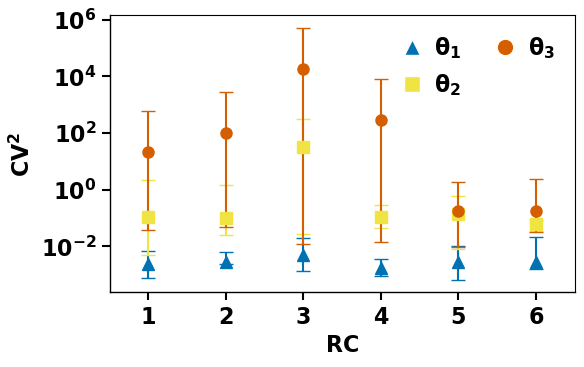

pca_svd_rc_mean_all:
[[[ 1.19191751e+01  7.34159327e+00 -1.49367750e-01]
  [ 1.29674025e+01 -2.68725348e+00  5.06772578e-01]
  [ 1.30945444e+01 -1.85248220e+00  9.01503384e-01]
  [ 1.27563686e+01  4.73801661e+00 -1.73148215e-01]
  [ 1.36324415e+01  1.41677356e+00 -2.96884805e-01]
  [ 1.27999525e+01  3.40439749e+00  1.29222855e-01]
  [ 1.20767212e+01  8.69562721e+00  1.54108191e-02]
  [ 1.20873251e+01  6.58359289e+00 -1.41067639e-01]
  [ 1.26226215e+01 -2.78595877e+00 -5.33658326e-01]
  [ 1.27265673e+01  2.97803330e+00 -2.13299900e-01]
  [ 1.24097881e+01  7.03825378e+00 -1.44730532e+00]
  [ 1.46667814e+01 -2.82387948e+00 -2.61084348e-01]
  [ 1.21905851e+01  5.59085274e+00 -1.68214306e-01]
  [ 1.19623604e+01  7.08062792e+00 -2.57893413e-01]
  [ 1.18001509e+01  8.18099022e+00 -6.16335273e-01]
  [ 1.32708626e+01  4.28490400e+00  2.51215315e+00]
  [ 1.39159298e+01 -3.73976678e-01  1.04650736e+00]
  [ 1.08227148e+01  9.68259239e+00 -1.04886413e+00]
  [ 1.26841383e+01 -2.37775922e+00 -2.09606

In [4]:
k_nei_list = [10]
K_list = [3]
L_list = [3, 6, 10, 15]
# L_list = [6, 10, 15]
# L_list = [6]

param_combinations = list(itertools.product(k_nei_list, K_list, L_list))

for k_nei, K, L in param_combinations:
    [k_nei, K, L] = [k_nei, K, L]
    print(f"[k_nei, K, L] = [{k_nei}, {K}, {L}]")
    data_name = "zebrafish_dynamo_part"
    figure_path= f"/home/linux/桌面/Is single cell sloppy?/14_画图/figure/cv_2/{data_name}/" + str([k_nei,K,L]) + "/"

    [pca_dim, k_rc, d_pca] = [50, 30, 10]

    clusters_name = "celltype"
    root_cluster = "Ngn3 low EP"
    loc_path_graph = 'upper right'
    basis = "umap"

    branch = [np.array(['Proliferating Progenitor', 'Pigment Progenitor', 'Melanophore']),
            np.array(['Proliferating Progenitor', 'Pigment Progenitor', 'Xanthophore']),
            np.array(['Proliferating Progenitor', 'Schwann Cell Precursor', 'Schwann Cell']) ]

    for t_list in (branch):
        branch_name = t_list[-1]

        adata0 = scv.read(data_path+data_name+'.h5ad', cache=True)
        adata = adata0.copy()
        scv.pp.pca(adata, n_comps=pca_dim)
        scv.pp.neighbors(adata, n_neighbors=k_nei)
        scv.pp.moments(adata, n_pcs=pca_dim, n_neighbors=k_nei)
        scv.tl.velocity(adata)
        print(adata)

        if branch_name == "Schwann Cell":
            nrc = 7
        else:
            nrc = 5

        # average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        # cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, rc_distance= "X_pca", n_nei=k_rc, dim_n=10)
        # average_path = np.array(adata[nearest_cell].obsm["X_umap"])[:5]
        # cell_arr = cell_arr[:5] 
        for nrc in [6]:
            average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}.npy') 
            print("average_path.shape", average_path.shape)
            cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, n_nei = k_rc, rc_distance= "X_umap")
            
            # fig = sc.pl.embedding(
            #     adata,
            #     # color=[clusters_name, "paga"],
            #     color=[clusters_name],
            #     basis="pca",
            #     color_map=cmap,
            #     return_fig=True
            # )

            X_pca = adata.obsm['X_pca']
            row = np.array([np.ones((k_nei,))*i for i in range(adata.shape[0])]).flatten()
            col = adata.uns['neighbors']['indices'].flatten()
            w_val = np.array([np.linalg.norm(X_pca[int(i),:]-X_pca[int(j),:]) for i,j in zip(row,col)])
            adj_val = np.ones(col.shape)
            A_mat = csr_matrix((adj_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            A = A_mat
            W_mat = csr_matrix((w_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
            dc=np.mean(w_val)
            cell_nei=adata.uns['neighbors']['indices']
            nei_w=[]
            rho_arr=[]
            for ni in adata.uns['neighbors']['indices']:
                dij=np.array([np.linalg.norm(X_pca[int(ni[0]),:]-X_pca[int(i),:]) for i in ni[1:]])
                rho=np.sum(np.exp(-dij**2/dc**2))
                nei_w.append(np.exp(-dij**2/dc**2)/np.sum(np.exp(-dij**2/dc**2)))
                rho_arr.append(rho)
                
            rho_arr=np.array(rho_arr)/np.amax(rho_arr)
            nei_w=np.array(nei_w)
            nei_w=np.hstack((np.ones((nei_w.shape[0],1)),nei_w))/2

            def smooth_func(X_val,cell_nei=cell_nei,nei_w=nei_w):
                X_s=X_val.copy()
                for ci in range(len(X_val)):
                    X_s[ci]=np.dot(X_val[cell_nei[ci,:]],nei_w[ci,:])
                return X_s

            if basis == "umap":
                X_umap = adata.obsm['X_umap']
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10
            elif basis == "pca":
                X_umap = adata.obsm['X_pca'][:, :2]
                X_plt = X_umap[:,0]
                Y_plt = X_umap[:,1]
                X_min = np.min(X_plt)
                X_max = np.max(X_plt)
                Y_min = np.min(Y_plt)
                Y_max = np.max(Y_plt)
                X_len = (X_max-X_min)/5
                Y_len = (Y_max-Y_min)/5
                wid = min(X_len,Y_len)/30
                X_ori = X_min-wid*10
                Y_ori = Y_min-wid*10

            X = torch.tensor(adata.layers['Ms'], dtype=torch.float32) 
            Encoder_path = "/home/linux/桌面/Is single cell sloppy?/11_PAGA_spectrum/encoder/"
            # for pca in [X_pca, eigengene, hotspot]:

            model_path = Encoder_path + data_name+' '+str([k_nei,K,L])+'/'
            eigengene = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_eigengene_X.npy")
            # hotspot = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_hs_X.npy")
            model_name = f"{model_path}encoder.pt"
            model = torch.load(f'{model_name}')
            mu, sigma = model(torch.tensor(X))
            mu_learned = mu.detach().numpy()

            sigma_learned = sigma.detach().numpy()
            Fisher_g=np.zeros((X.shape[0],L*2,L*2))
            for i in range(X.shape[0]):
                for j in range(L):
                    Fisher_g[i,j,j]=1/sigma_learned[i,j]**2
                    Fisher_g[i,L+j,L+j]=2/sigma_learned[i,j]**2
            Fisher_g_diag = np.zeros([X.shape[0],L*2])
            for i in range(X.shape[0]):
                Fisher_g_diag[i] = np.diag(Fisher_g[i])
            ## 1_1这一步用了一个神经网络 pca -> Z(mu,sigma), 然后求出这个网络的pZ_pEg。
            for pca in [eigengene]:
                print("pca.shape:", pca.shape)
                reset_seeds(0) # 0
                model = nn.Sequential(
                    nn.Linear(pca.shape[1], 128),
                    nn.ReLU(),
                    nn.Linear(128,64),
                    nn.ReLU(),
                    nn.Linear(64,2*L),
                )
                loss_fn = nn.MSELoss()
                optimizer = SGD(model.parameters(), lr=0.01, weight_decay=0.001)#, momentum=0.2
                x_in=torch.tensor(pca, dtype=torch.float32)
                latent_z = np.hstack((mu_learned,sigma_learned))
                x_out=torch.tensor(latent_z.astype(np.float32))
                for epoch in range(1000): # 200 # NOTE: 500和200的结果不一样。
                # for epoch in range(200): # 200
                    # break
                    optimizer.zero_grad()
                    output = model(x_in)
                    loss = loss_fn(output,x_out) 
                    loss.backward()
                    optimizer.step()
                pZ_ppca = p_out_p_in(pca, model, dim_out = 2 * L)

                ### 链式法则（已知FI_Z），求出FI_pca。
                FI_pca = np.einsum("ijk,ij,ijh->ikh",pZ_ppca, Fisher_g_diag, pZ_ppca)
                print("FI_pca.shape:", FI_pca.shape)
                # FI_Eg_diag = FI_Eg[:, range(eigengene.shape[1]), range(eigengene.shape[1])]
                # U_FI_Eg[i]的列向量是特征向量。Ax = /lamba x (从这可以看出x是列向量)
                # 不过U_FI_Eg[i]的行向量和列向量的模长都是1.而且行和行彼此正交。列和列彼此正交。这是因为UU_T = I. U是正交矩阵。
                U_FI_Eg, S_FI_Eg, Vt_FI_Eg = np.linalg.svd(FI_pca, full_matrices=False)
                print("svd后(U_FI_Eg, S_FI_Eg, Vt_FI_Eg)：",U_FI_Eg.shape, S_FI_Eg.shape, Vt_FI_Eg.shape)

                print("S_FI_Eg:", S_FI_Eg)

                # rc_path(adata, mu_learned, sigma_learned, average_path, basis, k_nei, data_name)
                cell_arr_plot(average_path, cell_arr, X_umap)
                # rc_path_celltype(adata, average_path, basis, data_name, save = save, figure_path = figure_path, branch_name  = branch_name)
                    
                dim = 3
                # U_FI_Eg和pca的各列都是正交的才可以这么算。cell_i_的pca坐标（向量）点积u1得到的就是u1的坐标，这其实就是在u1上做投影。
                # NOTE:这可能是为什么eigengene和hotspot不行的原因，eigengene的各坐标系间不是正交的。
                pca_svd_rc_variance_all, pca_svd_rc_mean_all= compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L, simple=dim/2, cv= True)
                pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])

                # print("pca_svd_rc_variance_all.shape",pca_svd_rc_variance_all[0].shape)
                # plot_all_variances_odd(pca_svd_rc_variance_all, share_y = False)
                FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, 0.5, cell_arr, norm=True, simple= True,
                                save = save, figure_path = figure_path, branch_name  = branch_name)

                exclude_indices = []
                all_indices = list(range(len(pca_svd_rc_variance_all)))
                keep_indices = [i for i in all_indices if i not in exclude_indices]
                new_array = np.array(pca_svd_rc_variance_all)[keep_indices]

                variance_along_rc(cell_arr, new_array, dim = dim, save = save, figure_path = figure_path, branch_name  = branch_name)

                print("pca_svd_rc_mean_all:")
                print(np.array(pca_svd_rc_mean_all))